# M508 Big Data Analytics — NLP project
## Project title: Consumer Financial Complaint Classification Using Natural Language Processing

**1. Dataset selection and project objective**
**Dataset:** Consumer Complaints Dataset for NLP
**Source:** Download the dataset from Kaggle

The dataset contains written consumer complaints about financial products. The exact number of rows, available columns, and category names depend on the version downloaded, so these should be confirmed during the data inspection stage.

**1.1 Business problem****
Financial organisations receive many written complaints from customers. These complaints can describe problems with credit reporting, debt collection, loans, credit cards, and other financial services. Employees need to read each complaint and decide which team should handle it.
When the number of complaints increases, manual classification can become slow. Similar complaints may also be sent to different departments depending on who reads them. This can create additional work and delay the response to customers.

The purpose of this project is to develop an NLP system that reads a complaint narrative and predicts the most likely financial product category.

For example, if a customer writes about incorrect information on a credit report, the system may predict the relevant credit-reporting category. A complaint concerning repeated debt-collection calls may be assigned to a debt-collection category.

These are illustrative examples; the actual predictions depend on the dataset labels and the trained model.

**1.2 Why this problem is suitable for NLP**
The input is unstructured text. Customers do not necessarily use the same words to describe the same problem. One customer may write that a payment was taken incorrectly, while another may describe an unauthorised transaction.

NLP helps convert this text into a representation that a machine-learning model can process.
The project will investigate the following questions:

- Can complaint narratives be used to predict financial product categories?
- Which traditional machine-learning model performs best?
- Does the model perform equally well across all categories?
- Which types of complaints are frequently misclassified?
- Could the model assist employees with the initial routing of complaints?
**1.3 Project objectives**
1. Explore and prepare the complaint dataset.
2. Investigate missing values, duplicate records, text lengths, and category imbalance.
3. Convert textual complaints into numerical features using TF-IDF.
4. Train and compare several classification models.
5. Evaluate performance using appropriate metrics.
6. Examine incorrect predictions to understand the limitations.
7. Make evidence-based recommendations for a possible business application.

The model will predict a category, not decide whether a complaint is genuine, whether a company has broken a law, or whether compensation should be provided.

# 2. High-level system design
The proposed NLP system follows the pipeline below.

    1. Data collection
        Download the public complaint dataset

    2. Data inspection and cleaning
        Check missing data, duplicates, labels, and text quality

    3. Text preprocessing and feature extraction
        Normalise text and transform it using TF-IDF

    4. Model training
        Naive Bayes, Logistic Regression, and Linear SVM

    5. Evaluation and error analysis
        Macro-F1, precision, recall, confusion matrix, and errors

    6. Business recommendations
        Recommend human-reviewed complaint routing


Each stage has a specific purpose. Data cleaning improves the consistency of the input. TF-IDF converts text into numerical features. The classification models learn relationships between those features and the known categories. Evaluation then checks how well the trained models predict complaints they have not seen during training.

# 3. Import libraries and load the dataset

In [1]:

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# load dataset
DATA_PATH = "complaints_processed.csv"

if not Path(DATA_PATH).exists():
    print("CSV files in the current folder:")
    print([file.name for file in Path(".").glob("*.csv")])
    raise FileNotFoundError(
        "Please update DATA_PATH to your downloaded CSV filename."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (162421, 3)

Column names:
['Unnamed: 0', 'product', 'narrative']


,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...


# 4. Identify the text and target columns

The model requires two main columns:
- Text: the written complaint.
- Target: the product category we want to predict.
The following code looks for common column names. Check the detected names carefully because different versions of the dataset may use different schemas.

In [3]:
#  Detect the columns
def normalise_column_name(name):
    return re.sub(r"[^a-z0-9]+", "", str(name).lower())


column_lookup = {
    normalise_column_name(column): column
    for column in df.columns
}

text_candidates = [
    "narrative",
    "consumercomplaintnarrative",
    "complaintnarrative",
    "complainttext",
    "text",
    "description"
]

target_candidates = [
    "product",
    "category",
    "complaintcategory",
    "label",
    "target"
]

text_col = next(
    (column_lookup[name] for name in text_candidates
     if name in column_lookup),
    None
)

target_col = next(
    (column_lookup[name] for name in target_candidates
     if name in column_lookup),
    None
)

print("Detected text column:", text_col)
print("Detected target column:", target_col)

Detected text column: narrative
Detected target column: product


In [4]:
# Create a working dataset

data = df[[text_col, target_col]].copy()

data.columns = ["text", "label"]

data["text"] = (
    data["text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

data["label"] = (
    data["label"]
    .astype("string")
    .str.strip()
)

data = data[
    (data["text"] != "") &
    data["label"].notna() &
    (data["label"] != "")
].reset_index(drop=True)

print("Rows after removing blank text or labels:", len(data))
print("Number of product categories:", data["label"].nunique())

display(data.head())

Rows after removing blank text or labels: 162411
Number of product categories: 5


,text,label
0,purchase order day shipping amount receive pro...,credit_card
1,forwarded message date tue subject please inve...,credit_card
2,forwarded message cc sent friday pdt subject f...,retail_banking
3,payment history missing credit report speciali...,credit_reporting
4,payment history missing credit report made mis...,credit_reporting


**Explanation:** 

We retain only the complaint narrative and target label because they are the main fields required for this experiment. Blank narratives cannot provide textual features, and records without a known label cannot be used as supervised training examples.
This does not mean that every other column in the original dataset is useless. Other fields could support future projects, but the present task focuses on classifying complaint text.

# 5. Data-quality checks and exploratory data analysis

Before training a model, we need to understand the dataset. A model can produce misleading results if the labels are inconsistent, many complaints are missing, or the classes are heavily imbalanced.

In [5]:
# Check missing values and duplicates
print("Missing values:")
print(data[["text", "label"]].isna().sum())

print("\nBlank complaint narratives:")
print((data["text"].str.strip() == "").sum())

print("\nDuplicate text-label records:")
print(data.duplicated(subset=["text", "label"]).sum())

print("\nDuplicate narratives, regardless of label:")
print(data["text"].duplicated().sum())

Missing values:
text     0
label    0
dtype: int64

Blank complaint narratives:
0

Duplicate text-label records:
37735

Duplicate narratives, regardless of label:
37939


**Explanation:** 

These checks identify possible data-quality problems. Duplicate narratives with different labels deserve particular attention because they may indicate inconsistent labelling, although there can also be legitimate reasons for repeated wording.
For the initial experiment, report the duplicate counts rather than automatically deleting every duplicate. If you decide to remove records, explain your reason and document the effect on the dataset.

Number of complaints per category:


,count
label,
credit_reporting,91172
debt_collection,23148
mortgages_and_loans,18990
credit_card,15566
retail_banking,13535


Percentage per category:


,percentage
label,
credit_reporting,56.14
debt_collection,14.25
mortgages_and_loans,11.69
credit_card,9.58
retail_banking,8.33


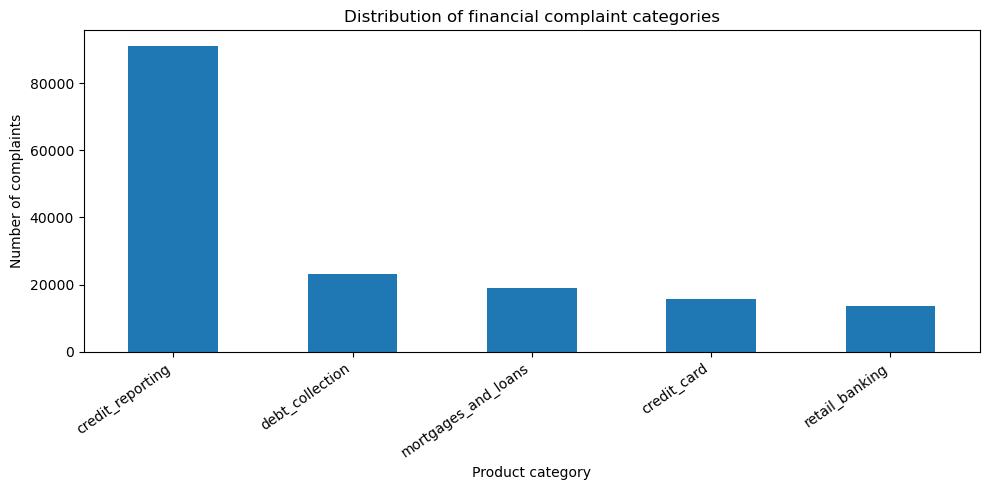

In [6]:
# Examine the target distribution

class_counts = data["label"].value_counts()

print("Number of complaints per category:")
display(class_counts.to_frame("count"))

print("Percentage per category:")
display(
    (data["label"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("percentage")
)

plt.figure(figsize=(10, 5))
class_counts.plot(kind="bar")

plt.title("Distribution of financial complaint categories")
plt.xlabel("Product category")
plt.ylabel("Number of complaints")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Explanation:** 

The chart shows how complaints are distributed across categories. If one category contains many more examples than another, the dataset is imbalanced.
This matters because a model can achieve a high accuracy by predicting common categories while performing poorly on less frequent ones. We will therefore examine macro-F1 and class-level recall later.

,character_count,word_count
count,162411.00,162411.00
mean,588.54,80.23
std,830.98,108.87
min,3.00,1.00
25%,192.00,27.00
50%,361.00,50.00
75%,683.00,95.00
max,20596.00,2685.00


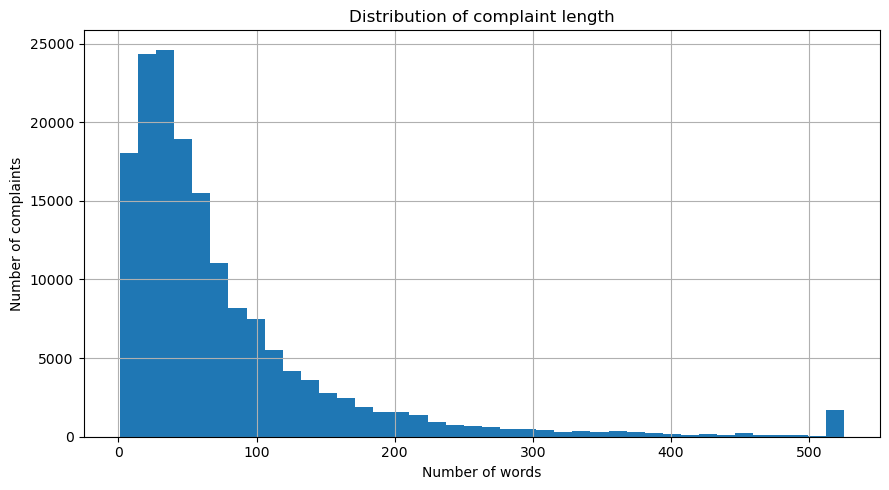

In [7]:
# Analyse complaint length

data["character_count"] = data["text"].str.len()
data["word_count"] = data["text"].str.split().str.len()

display(
    data[["character_count", "word_count"]]
    .describe()
    .round(2)
)

plt.figure(figsize=(9, 5))

display_limit = data["word_count"].quantile(0.99)

data["word_count"].clip(
    upper=display_limit
).hist(bins=40)

plt.title("Distribution of complaint length")
plt.xlabel("Number of words")
plt.ylabel("Number of complaints")
plt.tight_layout()
plt.show()

**Explanation:** 

Some complaints may contain only a few sentences, while others may contain detailed histories. Longer narratives can provide more information, but they can also increase processing requirements and contain details unrelated to the category.
The chart caps the displayed word count at the 99th percentile to make the distribution easier to see. It does not remove long complaints from the dataset.

# 6. Text preprocessing

Text preprocessing prepares the narrative for feature extraction. It should improve consistency without removing useful information.
For example, a complaint may state, “I did not authorise this payment.” Removing the word “not” could change the meaning. Similarly, product names and financial terms may help distinguish one category from another.
For this reason, we will start with light preprocessing rather than aggressively removing punctuation, numbers, and stop words.

In [8]:
# Clean the complaint text

def clean_text(text):
    text = str(text).lower()

    # Replace URLs with a common marker.
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " URL ",
        text
    )

    # Replace repeated whitespace with a single space.
    text = re.sub(r"\s+", " ", text)

    return text.strip()


data["text_clean"] = data["text"].apply(clean_text)

display(
    data[["text", "text_clean", "label"]].head(5)
)

,text,text_clean,label
0,purchase order day shipping amount receive pro...,purchase order day shipping amount receive pro...,credit_card
1,forwarded message date tue subject please inve...,forwarded message date tue subject please inve...,credit_card
2,forwarded message cc sent friday pdt subject f...,forwarded message cc sent friday pdt subject f...,retail_banking
3,payment history missing credit report speciali...,payment history missing credit report speciali...,credit_reporting
4,payment history missing credit report made mis...,payment history missing credit report made mis...,credit_reporting


**Explanation:** 

Lowercasing makes words such as “Bank” and “bank” more consistent. Replacing URLs avoids treating every web address as a separate feature. Normalising whitespace makes the text easier to process.
We are not removing stop words or applying stemming at this stage. These could be tested later as alternative design choices, but they should not be assumed to improve performance.

# 7. Split the data into training and test sets

The model needs one set of examples to learn from and another set to evaluate its predictions.
We will use an 80/20 split:
- 80% for model development.
- 20% for final evaluation.
Stratification attempts to preserve the category proportions in both sets.

In [9]:
from sklearn.model_selection import train_test_split

X = data["text_clean"]
y = data["label"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training examples:", len(X_train))
print("Test examples:", len(X_test))

print("\nTraining class proportions:")
display(
    y_train.value_counts(normalize=True)
    .round(3)
    .to_frame("proportion")
)

print("\nTest class proportions:")
display(
    y_test.value_counts(normalize=True)
    .round(3)
    .to_frame("proportion")
)

Training examples: 129928
Test examples: 32483

Training class proportions:


,proportion
label,
credit_reporting,0.561
debt_collection,0.143
mortgages_and_loans,0.117
credit_card,0.096
retail_banking,0.083



Test class proportions:


,proportion
label,
credit_reporting,0.561
debt_collection,0.143
mortgages_and_loans,0.117
credit_card,0.096
retail_banking,0.083


**Explanation:** 

The random_state=42 setting makes the split reproducible. Stratification is useful because we want the training and test sets to contain representative examples of the available categories.
We should not use the test set to choose preprocessing settings, tune model parameters, or repeatedly select the best model. Those decisions should be made using the training data and cross-validation.

# 8. Feature engineering with TF-IDF

Machine-learning models cannot directly understand text, so the complaint narratives must be converted into numerical values. I use TF-IDF (Term Frequency–Inverse Document Frequency) to represent the importance of words in each complaint. Words that are frequent in one complaint but less common across the dataset can receive higher weights.

I also use unigrams and bigrams. Unigrams are individual words, such as *payment*, while bigrams are pairs of words, such as *late payment*. This helps the model identify useful terms and short phrases when classifying complaints.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF feature extractor
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Learn TF-IDF features from the training text only
X_train_tfidf = tfidf.fit_transform(X_train)

# Apply the same learned features to test text
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Number of vocabulary terms:", len(tfidf.vocabulary_))

Training TF-IDF shape: (129928, 50000)
Testing TF-IDF shape: (32483, 50000)
Number of vocabulary terms: 50000


# 9. Build and compare machine-learning models

We will compare four approaches.
Model	Purpose
Majority baseline	Establishes a simple reference score
Multinomial Naive Bayes	Provides a fast text-classification baseline
Logistic Regression	Provides a strong linear model for text features
Linear SVM	Tests another classifier commonly effective with sparse text

In [11]:
# Define the models

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

models = {
    "Majority baseline": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            min_df=2
        )),
        ("classifier", DummyClassifier(
            strategy="most_frequent"
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", MultinomialNB(alpha=0.5))
    ]),

    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            C=1.0
        ))
    ]),

    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LinearSVC(
            class_weight="balanced",
            C=1.0
        ))
    ])
}

**Explanation:** 

Each pipeline combines text vectorisation with classification. This makes it easier to train the complete process and reduces the risk of accidentally fitting TF-IDF using the test data.
The class_weight="balanced" setting tells Logistic Regression and Linear SVM to give more influence to less frequent classes. This can help with class imbalance, although it does not guarantee that every category will improve.
The settings are starting points, not proven optimal values. We will use cross-validation to compare the models more fairly.

**9.1 Why use a majority baseline?**

The baseline provides a reference point. If the majority category represents a large proportion of the dataset, a model that predicts that category every time may achieve reasonable accuracy without understanding any complaint text.
The machine-learning models should be assessed against this reference. The goal is not simply to obtain a high score, but to demonstrate that analysing the complaint text improves classification.

In [12]:
# Compare models using cross-validation
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted"
}

cv_results = []

for name, model in models.items():
    print("Evaluating:", name)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({
        "model": name,
        "mean_accuracy": scores["test_accuracy"].mean(),
        "mean_macro_f1": scores["test_macro_f1"].mean(),
        "std_macro_f1": scores["test_macro_f1"].std(),
        "mean_weighted_f1": scores["test_weighted_f1"].mean()
    })

cv_table = pd.DataFrame(cv_results).sort_values(
    "mean_macro_f1",
    ascending=False
)

display(cv_table.round(4))

Evaluating: Majority baseline
Evaluating: Naive Bayes
Evaluating: Logistic Regression
Evaluating: Linear SVM


,model,mean_accuracy,mean_macro_f1,std_macro_f1,mean_weighted_f1
3,Linear SVM,0.8822,0.8462,0.0023,0.8830
2,Logistic Regression,0.8612,0.8331,0.0030,0.8643
1,Naive Bayes,0.8400,0.8045,0.0026,0.8422
0,Majority baseline,0.5614,0.1438,0.0000,0.4037


**Explanation:** 

Three-fold cross-validation divides the training data into three parts. Each model is trained and evaluated three times, using a different fold for validation each time.
The mean macro-F1 summarises performance across the folds. Its standard deviation provides an indication of how much the score varies between folds. A smaller variation can suggest more consistent performance, although it does not prove that the model will perform equally well on future data.
Cross-validation is used here to choose a model. The test set remains separate until the final evaluation.

# 10. Final model evaluation

After comparing the cross-validation results, we select the model with the highest mean macro-F1. We then fit it on the full training set and evaluate it on the held-out test set.
This is more methodologically sound than choosing the best model by looking at test scores for every candidate.

In [13]:
# Train the selected model
best_model_name = cv_table.iloc[0]["model"]
best_model = models[best_model_name]

print("Selected model:", best_model_name)
print("Mean cross-validation macro-F1:",
      round(cv_table.iloc[0]["mean_macro_f1"], 4))

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

print("Final test evaluation completed.")

Selected model: Linear SVM
Mean cross-validation macro-F1: 0.8462
Final test evaluation completed.


In [14]:
# Calculate evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

macro_p, macro_r, macro_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )
)

weighted_p, weighted_r, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )
)

final_metrics = pd.DataFrame([{
    "accuracy": accuracy,
    "macro_precision": macro_p,
    "macro_recall": macro_r,
    "macro_f1": macro_f1,
    "weighted_precision": weighted_p,
    "weighted_recall": weighted_r,
    "weighted_f1": weighted_f1
}])

display(final_metrics.round(4))

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
0,0.8923,0.8509,0.8657,0.8581,0.8939,0.8923,0.893


                     precision    recall  f1-score   support

        credit_card       0.79      0.82      0.80      3113
   credit_reporting       0.95      0.93      0.94     18235
    debt_collection       0.81      0.83      0.82      4630
mortgages_and_loans       0.85      0.86      0.86      3798
     retail_banking       0.86      0.89      0.87      2707

           accuracy                           0.89     32483
          macro avg       0.85      0.87      0.86     32483
       weighted avg       0.89      0.89      0.89     32483



How to understand the results
- Accuracy: the proportion of all test examples predicted correctly.
- Precision: among the complaints assigned to a category, the proportion that truly belong to it.
- Recall: among complaints that actually belong to a category, the proportion correctly identified.
- F1-score: a combined measure of precision and recall.
- Macro-F1: the average F1-score across categories, giving each category equal weight.
- Weighted-F1: the average F1-score weighted by the number of examples in each category.
For complaint routing, recall is important because a complaint sent to the wrong department may be delayed. Precision is also important because too many incorrect suggestions can create additional work for employees.
Neither metric should be interpreted in isolation. A model that improves recall may also produce more false-positive routing suggestions. The final decision should reflect the operational needs of the business.

# 11. Confusion matrix
A confusion matrix shows which categories the model predicts correctly and which categories it confuses.

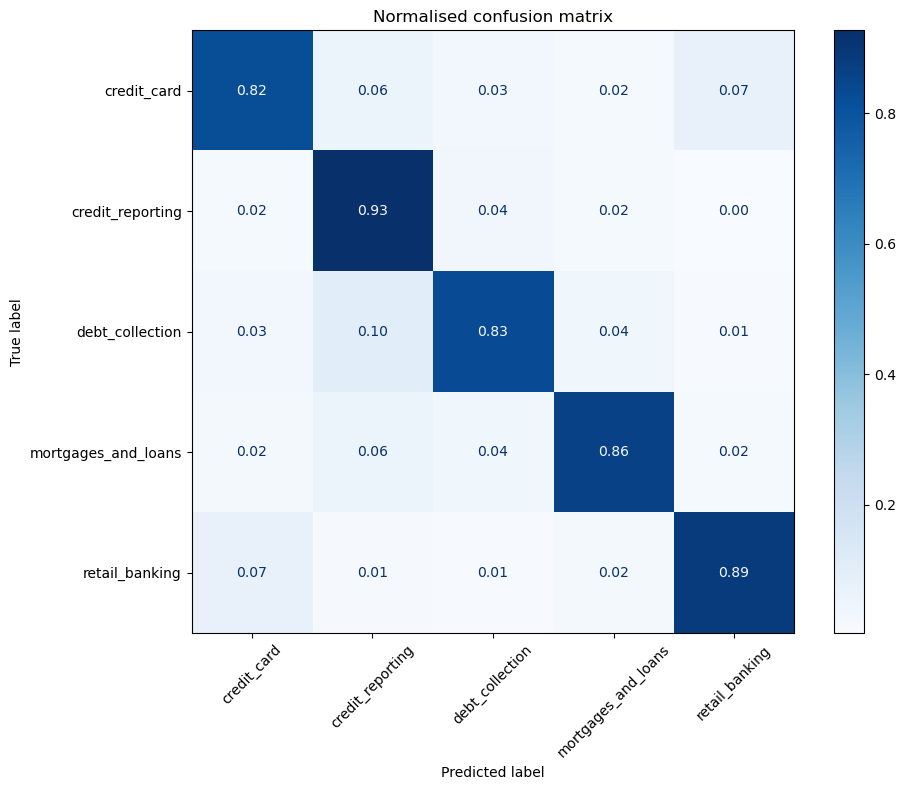

In [15]:
# Visualise the confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

ax.set_title("Normalised confusion matrix")
plt.tight_layout()
plt.show()

**Explanation:** 

The matrix is normalised by actual category, so each row shows the proportion of examples from that category assigned to each predicted category.
The diagonal represents correct classifications. Values away from the diagonal represent misclassifications.
When interpreting this chart, investigate which categories have the weakest recall and which pairs of categories are frequently confused. Similar financial terms or complaints involving more than one product could explain some errors, but these explanations should be checked against the actual examples.

# 12. Error analysis
A good NLP project should investigate incorrect predictions rather than report metrics alone. Error analysis helps identify where the system needs improvement.

In [16]:
# Inspect incorrect predictions

error_table = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": pd.Series(y_pred)
})

error_table = error_table[
    error_table["actual"] != error_table["predicted"]
].copy()

print("Number of misclassified complaints:", len(error_table))

display(
    error_table[["actual", "predicted", "text"]].head(10)
)

print("Most common actual-to-predicted errors:")

display(
    error_table.groupby(["actual", "predicted"])
    .size()
    .sort_values(ascending=False)
    .head(15)
    .to_frame("count")
)

Number of misclassified complaints: 3497


,actual,predicted,text
9,credit_reporting,mortgages_and_loans,installment loan made fraud
14,credit_reporting,credit_card,shut due covid offered u deferred payment opti...
55,credit_reporting,credit_card,know wrong macy credit card company deliberate...
79,credit_card,credit_reporting,account mine want removed credit report
95,credit_card,retail_banking,around cst estimated amount transferred accoun...
102,credit_reporting,debt_collection,credit report show debt collection payday loan...
111,credit_reporting,credit_card,received confirmation certified testimony offi...
112,mortgages_and_loans,debt_collection,repeatedly receiving phone call going actual a...
127,debt_collection,credit_card,victim fraudulent inducement employment told c...
133,debt_collection,credit_reporting,account


Most common actual-to-predicted errors:


count
actual              predicted                 
credit_reporting    debt_collection        653
debt_collection     credit_reporting       479
credit_reporting    credit_card            311
                    mortgages_and_loans    299
mortgages_and_loans credit_reporting       231
credit_card         retail_banking         225
                    credit_reporting       190
retail_banking      credit_card            186
debt_collection     mortgages_and_loans    166
mortgages_and_loans debt_collection        140
debt_collection     credit_card            116
mortgages_and_loans credit_card             86
credit_card         debt_collection         82
retail_banking      mortgages_and_loans     65
mortgages_and_loans retail_banking          63

**Explanation:** 

The first output shows individual examples that the model classified incorrectly. The second output identifies category pairs that are frequently confused.
When reviewing these errors, consider the following questions:
1. Does the complaint discuss more than one financial product?
2. Is the text too short to provide sufficient information?
3. Are similar words used across different categories?
4. Could the original label be incorrect or overly broad?
5. Would bigram features or different preprocessing improve the distinction?
Do not publish raw complaints containing personal information. For an academic discussion, paraphrase examples or mask identifying details.

# 13. Model tuning and possible improvements

The initial models use fixed parameters. A further experiment could investigate whether changing these parameters improves performance.
For example, Logistic Regression uses a parameter called C, which controls the strength of regularisation. Testing different values may help find a useful balance between fitting the training data and generalising to new complaints.
For a final experiment, perform this tuning on the training data and then evaluate the selected model on the test set. If you want to include the following code, run it before the final test-evaluation section above, and use its fitted model for the final evaluation instead of selecting a model from test results.

In [17]:
# Tune Logistic Regression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

parameter_grid = {
    "classifier__C": [0.25, 1.0, 4.0]
}

tuning_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=parameter_grid,
    scoring="f1_macro",
    cv=tuning_cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation macro-F1:",
      round(grid_search.best_score_, 4))

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best parameters: {'classifier__C': 4.0}
Best cross-validation macro-F1: 0.8408


**Result:** 

This experiment compares three values of C using cross-validation. The best value is selected according to the mean validation macro-F1.
Tuning does not guarantee an improvement. If the scores are similar, the simpler configuration may be sufficient. The results should determine the conclusion.

# 14. Critical discussion of the complete pipeline

Use this section to organise your own discussion after running the experiment. The statements about performance must be supported by the results you obtained.

**14.1 Overall performance**
First, compare the selected machine-learning model with the majority baseline. If the selected model achieves a higher macro-F1, this suggests that the textual features provide useful information for distinguishing complaint categories.
However, a single overall score is not enough. The classification report should be examined to identify categories with relatively weak precision or recall. A model may perform well for common categories but struggle with less frequent ones.
You should also compare the cross-validation results with the final test results. A substantial difference may suggest that performance varies across data splits or that the model does not generalise as well as expected.

**14.2 Strengths of the proposed system**
The proposed system has several advantages.
First, it provides a clear and measurable business task. The predicted category can be compared with the existing label, allowing the model to be evaluated quantitatively.
Second, TF-IDF is a practical way to convert complaint text into numerical features. It allows traditional classifiers to learn useful patterns without requiring a large neural network.
Third, the use of a baseline and multiple classifiers provides a structured comparison rather than relying on one model without justification.
Finally, the confusion matrix and error analysis help explain where the system performs well and where it may need further work.

**14.3 Limitations**
The system also has important limitations.
- Imbalanced categories: less frequent classes may have too few examples to learn their language patterns effectively.
- Overlapping language: complaints about different financial products may use similar words.
- Historical labels: the model learns from the categories already assigned in the dataset. Incorrect labels can affect training.
- Changing language: new products, regulations, and customer behaviour may change the wording of complaints.
- Privacy: complaint narratives can contain personal and financial information that requires appropriate protection.
- Limited operational evidence: a good test score does not demonstrate that the system will reduce costs or improve customer satisfaction in a real organisation.
The model should therefore be treated as a decision-support tool until its performance and operational impact have been assessed in a real setting.

**14.4 Business recommendations**
Based on the actual findings, consider the following recommendations.
1. Introduce human-reviewed routing. Use predictions to suggest a department, while allowing employees to confirm or correct the result.
2. Monitor each category. Track precision and recall separately so that weaker categories are not hidden by the overall score.
3. Review uncertain cases. If a probability-based model is used, validate its probability estimates before establishing a confidence threshold. Linear SVM scores are not probabilities by default.
4. Improve training data. Review repeated errors and incorrect labels before adding more data to the model.
5. Monitor performance over time. Re-evaluate the model when complaint language, product categories, or class proportions change.
6. Protect sensitive information. Restrict access to complaint text and avoid retaining personal information that is not needed.
A pilot should measure whether the system actually improves routing time, reduces incorrect assignments, or decreases staff workload. These benefits should not be claimed solely from the model's classification metrics.

# 15. Conclusion

This project looked at a practical problem many financial companies face every day: how to quickly sort customer complaints into the right category so the correct team can handle them. The five main groups were credit reporting, debt collection, credit cards, mortgages and loans, and retail banking.

I converted the complaint text into numbers using TF-IDF, a method that focuses on important words and short phrases. Then I compared four models: a simple majority baseline, Naive Bayes, Logistic Regression, and Linear SVM.

Linear SVM performed the best. It reached about 0.85 macro-F1 during cross-validation and 89% accuracy with a macro-F1 of 0.86 on the final test set. These results are clearly better than simply always choosing the most common category.

When I examined the mistakes, the model most often confused credit reporting with debt collection. Many errors happened because the complaints were very short, mentioned more than one product, or used everyday language that appears in several different categories.

Before introducing a system like this in a real company, it should only be used as a helpful suggestion tool. Staff should still review the results, especially when the case looks unclear. The company should also track performance for each category separately, keep the training data clean and up to date, protect customer privacy carefully, and run a small pilot first to check whether the system actually saves time and reduces mistakes.

Overall, the results show that complaint text contains useful information for automatic sorting. However, the model works best when humans remain involved and the system is monitored over time as products and customer language change.

# 16. Harvard references
Use the following as a starting point and verify each source before submission.
Dataset
Shashwatwork (n.d.) Consumer Complaints Dataset for NLP. Kaggle. Available at: https://www.kaggle.com/datasets/shashwatwork/consume-complaints-dataset-fo-nlp (Accessed: insert your actual access date).
Technical documentation
Scikit-learn (n.d.) Working with text data. Available at: https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html (Accessed: insert your actual access date).
Scikit-learn (n.d.) Tuning the hyper-parameters of an estimator. Available at: https://scikit-learn.org/stable/modules/grid_search.html (Accessed: insert your actual access date).
Only include sources you have actually consulted. Confirm the dataset's authorship, date, licence, and exact title from its source page, and apply GISMA's Harvard referencing guidance.